# Dinámica inmobiliaria en el Eje Cafetero
## Parte I – Características de calidad de los datos

- **Fuente:** base limpia oficial, generada con `src/igac_inmobiliario/pipeline.py`. Para reproducirla sin volverla a descargar por favor usar: `python -m src.igac_inmobiliario.pipeline --desde-raw`.
- **Las banderas de calidad** se definen en `src/igac_inmobiliario/cleaning.py`. Este notebook muestra su medición.
- **El valor** de la base de datos es el declarado en la escritura, en pesos corrientes. No es el valor comercial del inmueble.

In [1]:
# Configuración y carga
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Ubicar la raíz del repo (la carpeta que contiene src/)
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.igac_inmobiliario.scope import ANALYSIS_COLUMNS

d = pd.read_csv(RAIZ / "data/processed/compraventas_eje_cafetero_completo_limpio.csv", dtype=str)
d["valor"] = pd.to_numeric(d["valor"])
d["year_radica"] = pd.to_numeric(d["year_radica"]).astype("Int64")
d["fecha_escritura"] = pd.to_datetime(d["fecha_escritura"])
d["anio_escritura"] = d["fecha_escritura"].dt.year
banderas = [c for c in d.columns if d[c].isin(["True", "False"]).all()]
d[banderas] = d[banderas].eq("True")

ficha = json.loads((RAIZ / "data/raw/compraventas_eje_cafetero_completo_descarga.json").read_text(encoding="utf-8"))
campos_fuente = [c.strip() for c in ANALYSIS_COLUMNS.split(",")]
print(f"Registros: {len(d):,} | Campos consultados a la fuente: {len(campos_fuente)}")
print(f"Descarga: {ficha['fecha_descarga_utc']} | Portal actualizado: {ficha['portal_actualizado_utc']}")
print(f"Filas esperadas: {ficha['filas_esperadas']:,} | Filas descargadas: {ficha['filas_descargadas']:,}")

Registros: 457,558 | Campos consultados a la fuente: 24
Descarga: 2026-11-13T19:15:55+00:00 | Portal actualizado: 2025-04-04T17:58:44+00:00
Filas esperadas: 457,558 | Filas descargadas: 457,558


## 1.1 Fuentes de datos y granularidad

### Varianza de la agregación

Cuando los registros se resumen por grupo, por ejemplo con el valor típico de cada municipio en cada año, parte de la información sobre cada venta se pierde. Esta sección mide cuánto se pierde. 

Las diferencias de valor entre compraventas tienen dos orígenes: dónde y cuándo ocurrió la venta, y qué se vendió. Lo primero se conserva al resumir por municipio y año; lo segundo no, porque dentro de un mismo municipio y año conviven apartamentos, casas y lotes de tamaños muy distintos. La tabla muestra, para varios niveles de resumen, qué porcentaje de las diferencias se conserva y qué porcentaje se pierde. Si la mayor parte se pierde, el valor típico del municipio es una mala referencia para una venta concreta. Como la base no informa el área ni el tipo de inmueble, la alternativa es comparar cada folio consigo mismo en dos momentos, que es el principio de las ventas repetidas de este proyecto.

El cálculo usa el logaritmo del valor, para que las diferencias se lean en porcentaje y no en pesos, y excluye los valores que no corresponden a un precio individual (el total de una escritura paquete repetido en cada folio y las escrituras de otra época), para no confundir el efecto del resumen con problemas de calidad ya identificados.

In [2]:
base_agregacion = d[d["incluido_universo_modelado"] & ~d["valor_repetido_en_paquete"] & ~d["escritura_rezagada"]].copy()
base_agregacion["log_valor"] = np.log(base_agregacion["valor"])
varianza_total = base_agregacion["log_valor"].var(ddof=0)

niveles = {
    "Año": ["anio_escritura"],
    "Departamento-año": ["departamento", "anio_escritura"],
    "Municipio-año": ["divipola", "anio_escritura"],
    "Municipio-año-zona": ["divipola", "anio_escritura", "tipo_predio_zona"],
}
filas = []
for nombre, llaves in niveles.items():
    grupos = base_agregacion.groupby(llaves)["log_valor"]
    dentro = ((base_agregacion["log_valor"] - grupos.transform("mean")) ** 2).mean()
    tamanos = grupos.size()
    filas.append({
        "nivel": nombre,
        "grupos": len(tamanos),
        "% varianza entre grupos (se conserva)": (1 - dentro / varianza_total) * 100,
        "% varianza dentro de grupos (se pierde)": dentro / varianza_total * 100,
        "% grupos con < 30 registros": (tamanos < 30).mean() * 100,
    })
tabla_agregacion = pd.DataFrame(filas).set_index("nivel")
print(f"Registros usados: {len(base_agregacion):,} | Varianza total del log-valor: {varianza_total:.3f}")
display(tabla_agregacion)

Registros usados: 338,941 | Varianza total del log-valor: 1.892


,grupos,% varianza entre grupos (se conserva),% varianza dentro de grupos (se pierde),% grupos con < 30 registros
nivel,,,,
Año,10,3.60,96.40,0.00
Departamento-año,30,5.52,94.48,0.00
Municipio-año,478,16.62,83.38,12.76
Municipio-año-zona,1039,18.52,81.48,28.10


### Fuentes complementarias

En la Entrega 2 se identificaron cuatro fuentes públicas (Tabla 7). Ninguna se publica mediante una API: se descargan como anexos en Excel desde los portales del DANE y desde SUAMECA (Banco de la República), y se guardan en `data/raw/fuentes/` (no se suben a GitHub). Ninguna llega al nivel de la transacción, de modo que el cruce exige llevar la fuente principal a la granularidad de cada una.

| Fuente | Qué mide | Nivel territorial | Frecuencia | Cobertura en el Eje Cafetero 2015–2023 | Llave de cruce | Estado |
|---|---|---|---|---|---|---|
| IPC (DANE) | Variación de los precios al consumidor | Nacional | Mensual | Todo el territorio (dato nacional) | Año y mes de la escritura | **Integrado**: valores en pesos constantes |
| IPVN (DANE) | Variación del precio por m² de vivienda nueva | Áreas urbanas y metropolitanas | Trimestral | Pereira AU (Pereira y Dosquebradas), Armenia AU, Manizales AU (Manizales y Villamaría) | DIVIPOLA + año de la escritura | **Integrado**: contraste de tendencias |
| Tasas de colocación (Banco de la República) | Tasa de los créditos de adquisición de vivienda VIS y no VIS en pesos (total establecimientos) | Nacional | Mensual | Igual para todo el territorio | Año y mes de la escritura | **Integrado** como contexto macroeconómico |

Las dos series del DANE se publican como variaciones porcentuales y se encadenan para obtener índices (`src/igac_inmobiliario/fuentes_complementarias.py`). Como se trabaja con variaciones, no hace falta empalmar bases. El IPVN mide solo vivienda nueva y por metro cuadrado, mientras que el registro del IGAC incluye todo tipo de inmueble y no informa el área: sirve para comparar tendencias, no niveles. Se usa el IPC nacional porque el anexo por ciudades no cubre 2015–2016; la inflación local puede diferir de la nacional.

In [3]:
from src.igac_inmobiliario.fuentes_complementarias import (
    AREAS_IPVN_EJE, cargar_ipc, cargar_ipvn, cargar_tasas_vivienda, ipvn_por_municipio_anio)

FUENTES = RAIZ / "data/raw/fuentes"
ipc = cargar_ipc(FUENTES / "anex-IPC-Variacion-oct2026.xlsx")
ipvn = cargar_ipvn(FUENTES / "anex-IPVN-IVtrim2023.xls")
tasas = cargar_tasas_vivienda(FUENTES / "tasas_colocacion_vivienda_2015_2023.xlsx")
print(f"Tasas de vivienda: {len(tasas)} meses ({tasas['anio'].min()}-{tasas['anio'].max()}), vacíos: {int(tasas.isna().sum().sum())}")

# Control 1: la inflación anual reconstruida coincide con la publicada por el DANE (diferencias de redondeo)
dic = ipc[ipc["mes"] == 12].set_index("anio")["ipc"]
print("Inflación anual reconstruida (%):", ((dic / dic.shift(1) - 1) * 100).loc[2015:2023].round(2).to_dict())

# Control 2: el IPVN encadenado reproduce la variación anual publicada
ipvn["anual_calculada"] = (ipvn["ipvn"] / ipvn.groupby("area")["ipvn"].shift(4) - 1) * 100
control = ipvn.dropna(subset=["anual_calculada", "variacion_anual_publicada"])
control = control[control["anio"] >= 2015]
print(f"IPVN: {len(control)} trimestres comparados | diferencia máxima: {(control['anual_calculada'] - control['variacion_anual_publicada']).abs().max():.3f} puntos")

Tasas de vivienda: 108 meses (2015-2023), vacíos: 0
Inflación anual reconstruida (%): {2015: 6.77, 2016: 5.75, 2017: 4.09, 2018: 3.17, 2019: 3.8, 2020: 1.61, 2021: 5.63, 2022: 13.13, 2023: 9.27}
IPVN: 140 trimestres comparados | diferencia máxima: 0.020 puntos


,registros con dato,% de la base
IPC (año y mes de la escritura),"457,233.00",99.93
IPVN (municipio y año de la escritura),"322,917.00",70.57
Tasas de vivienda (año y mes de la escritura),"453,049.00",99.01


Escrituras sin IPC (anteriores a 2003): 325


,,registros
divipola,municipio,
17001,MANIZALES,71520
17873,VILLAMARÍA,9973
63001,ARMENIA,90738
66001,PEREIRA,98207
66170,DOSQUEBRADAS,53114


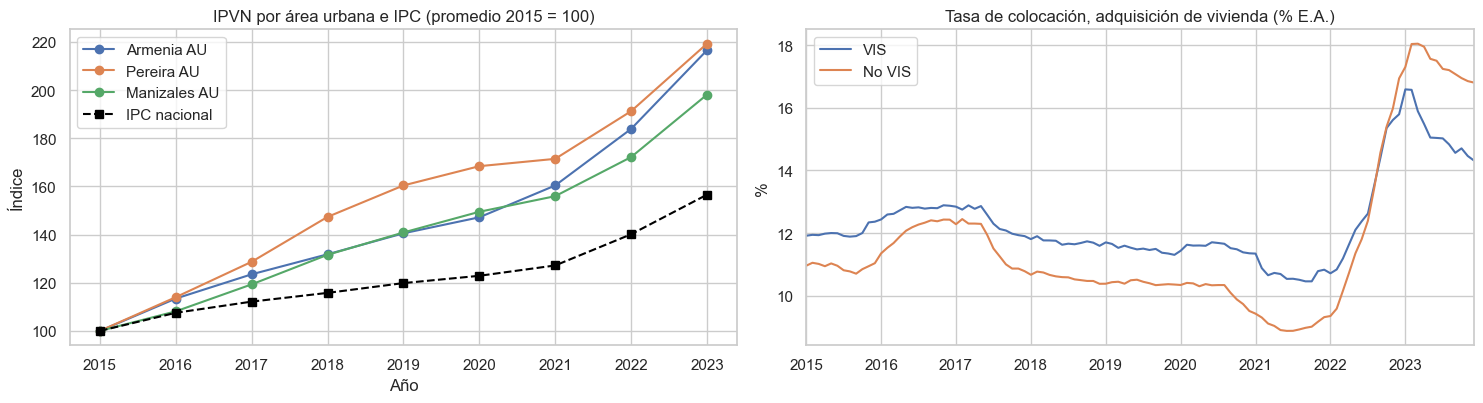

anio,2015,2016,2017,2018,2019,2020,2021,2022,2023
tasa promedio anual (%),,,,,,,,,
tasa_vis,12.01,12.75,12.42,11.72,11.50,11.55,10.70,13.01,15.21
tasa_no_vis,10.92,12.08,11.65,10.58,10.41,10.17,9.08,12.64,17.37


In [12]:
# Cruce con la base del IGAC
d["mes_escritura"] = d["fecha_escritura"].dt.month
d = d.merge(ipc[["anio", "mes", "ipc"]].rename(columns={"anio": "anio_escritura", "mes": "mes_escritura"}),
            on=["anio_escritura", "mes_escritura"], how="left")
ipvn_mun = ipvn_por_municipio_anio(ipvn).rename(columns={"anio": "anio_escritura"})
d = d.merge(ipvn_mun, on=["divipola", "anio_escritura"], how="left")
d = d.merge(tasas[["anio", "mes", "tasa_vis", "tasa_no_vis"]].rename(columns={"anio": "anio_escritura", "mes": "mes_escritura"}),
            on=["anio_escritura", "mes_escritura"], how="left")

cruce = pd.DataFrame({
    "registros con dato": [int(d["ipc"].notna().sum()), int(d["ipvn_promedio"].notna().sum())],
    "% de la base": [d["ipc"].notna().mean() * 100, d["ipvn_promedio"].notna().mean() * 100],
}, index=["IPC (año y mes de la escritura)", "IPVN (municipio y año de la escritura)"])
cruce.loc["Tasas de vivienda (año y mes de la escritura)"] = [d["tasa_vis"].notna().sum(), d["tasa_vis"].notna().mean() * 100]
display(cruce)
print("Escrituras sin IPC (anteriores a 2003):", int(d["ipc"].isna().sum()))

# Municipios del IPVN presentes en la base: si alguno da 0, revisar su DIVIPOLA
divipolas_ipvn = [c for codigos in AREAS_IPVN_EJE.values() for c in codigos]
display(d[d["divipola"].isin(divipolas_ipvn)].groupby(["divipola", "municipio"]).size().rename("registros").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ipvn_anual = ipvn[ipvn["anio"].between(2015, 2023)].groupby(["area", "anio"])["ipvn"].mean().unstack(0)
ipvn_anual[list(AREAS_IPVN_EJE)].plot(ax=axes[0], marker="o")
# IPC nacional, promedio anual, con la misma base que el IPVN (2015 = 100)
ipc_anual = ipc[ipc["anio"].between(2015, 2023)].groupby("anio")["ipc"].mean()
(ipc_anual / ipc_anual.loc[2015] * 100).plot(ax=axes[0], color="black", linestyle="--", marker="s", label="IPC nacional")
axes[0].legend()
axes[0].set_title("IPVN por área urbana e IPC (promedio 2015 = 100)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Índice")
tasas_mensual = tasas.assign(fecha=pd.to_datetime(dict(year=tasas["anio"], month=tasas["mes"], day=1))).set_index("fecha")
tasas_mensual[["tasa_vis", "tasa_no_vis"]].rename(columns={"tasa_vis": "VIS", "tasa_no_vis": "No VIS"}).plot(ax=axes[1])
axes[1].set_title("Tasa de colocación, adquisición de vivienda (% E.A.)")
axes[1].set_xlabel("")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()
display(tasas.groupby("anio")[["tasa_vis", "tasa_no_vis"]].mean().T.rename_axis("tasa promedio anual (%)"))

## 1.2 Definición del universo de análisis

La verificación de los actos de compraventa está en `scripts/01_actos_compraventa.py`. Aquí se confirma que la base descargada corresponde al universo definido.

In [5]:
print("Actos jurídicos presentes:", d["nombre_natujur"].value_counts().to_dict())
print("Departamentos:", d["departamento"].value_counts().to_dict())
print(f"Años de radicación: {d['year_radica'].min()}–{d['year_radica'].max()} | Municipios: {d['divipola'].nunique()}")
print(f"pk únicos: {d['pk'].nunique():,} de {len(d):,} registros")

Actos jurídicos presentes: {'COMPRAVENTA': 457558}
Departamentos: {'RISARALDA': 185392, 'CALDAS': 143986, 'QUINDÍO': 128180}
Años de radicación: 2015–2023 | Municipios: 53
pk únicos: 457,558 de 457,558 registros


## 1.4 Completitud

Completitud de los campos tal como vienen de la fuente (sin las columnas creadas en la limpieza), y cobertura del valor por departamento, año y oficina de registro.

In [6]:
completitud = pd.DataFrame({
    "vacíos": d[campos_fuente].isna().sum(),
    "% vacíos": d[campos_fuente].isna().mean() * 100,
}).sort_values("% vacíos", ascending=False)
display(completitud[completitud["vacíos"] > 0])
print("Campos 100% completos:", ", ".join(completitud.index[completitud["vacíos"] == 0]))

,vacíos,% vacíos
folios_derivados,457498,99.99
fecha_radica_texto,390873,85.43
fecha_apertura_texto,351749,76.88
estado_folio,23193,5.07
valor,15527,3.39


Campos 100% completos: year_radica, matricula, pk, departamento, divipola, orip, municipio, num_anotacion, categoria_ruralidad_2024, dinamica_2024, tipo_predio_zona, cod_natujur, nombre_natujur, count_a, documento_justificativo, count_de, predios_nuevos, tiene_valor, tiene_mas_de_un_valor


In [7]:
# % de registros con valor válido, por departamento y año de radicación
cobertura_valor = d.pivot_table(index="departamento", columns="year_radica",
                                values="valor_valido", aggfunc="mean") * 100
display(cobertura_valor.round(1))

# Oficinas de registro con algún año por debajo del 30% de su volumen promedio
por_orip = d.pivot_table(index="orip", columns="year_radica", values="pk", aggfunc="size", fill_value=0)
caida = por_orip.lt(por_orip.mean(axis=1) * 0.3, axis=0)
print(f"Oficinas de registro: {len(por_orip)} | Con algún año por debajo del 30% de su volumen promedio: {int(caida.any(axis=1).sum())}")
display(por_orip[caida.any(axis=1)])

year_radica,2015,2016,2017,2018,2019,2020,2021,2022,2023
departamento,,,,,,,,,
CALDAS,95.00,92.50,93.00,92.60,93.50,92.80,96.60,99.90,99.90
QUINDÍO,94.10,89.00,89.20,90.20,89.70,90.20,96.00,100.00,100.00
RISARALDA,99.70,99.80,99.70,99.60,99.80,99.60,99.80,99.80,99.80


Oficinas de registro: 19 | Con algún año por debajo del 30% de su volumen promedio: 0


year_radica,2015,2016,2017,2018,2019,2020,2021,2022,2023
orip,,,,,,,,,


## 1.5 Consistencia

Resumen de las banderas de calidad. Las cifras coinciden con `data/processed/perfil_calidad_completo.json`.

In [8]:
banderas_informe = {
    "Sin valor positivo informado": "valor_simbolico_o_invalido",
    "Valor simbólico": "valor_simbolico",
    "Anotación duplicada": "anotacion_duplicada",
    "Radicación anterior a la escritura": "radicacion_antes_de_escritura",
    "Escritura rezagada (dos o más años)": "escritura_rezagada",
    "En escritura paquete": "escritura_paquete",
    "Valor total repetido en cada folio del paquete": "valor_repetido_en_paquete",
    "Universo modelado": "incluido_universo_modelado",
}
tabla_consistencia = pd.DataFrame({
    "registros": {k: int(d[v].sum()) for k, v in banderas_informe.items()},
    "% de la base": {k: d[v].mean() * 100 for k, v in banderas_informe.items()},
})
display(tabla_consistencia)

# Valor mediano según los años entre la escritura y la radicación
rezago = pd.to_numeric(d["rezago_escritura_anios"])
orden_tramos = ["negativo", "0", "1", "2", "3-5", "6-10", "más de 10"]
tramos = pd.cut(rezago, bins=[-1000, -1, 0, 1, 2, 5, 10, 1000], labels=orden_tramos)
tabla_rezago = pd.DataFrame({
    "registros": tramos.value_counts(),
    "% de la base": tramos.value_counts(normalize=True) * 100,
    "valor mediano (millones)": d["valor"].groupby(tramos, observed=True).median() / 1e6,
}).reindex(orden_tramos)
display(tabla_rezago)

,registros,% de la base
Sin valor positivo informado,16047,3.51
Valor simbólico,616,0.13
Anotación duplicada,3254,0.71
Radicación anterior a la escritura,4058,0.89
Escritura rezagada (dos o más años),2835,0.62
En escritura paquete,163916,35.82
Valor total repetido en cada folio del paquete,97105,21.22
Universo modelado,437648,95.65


,registros,% de la base,valor mediano (millones)
rezago_escritura_anios,,,
negativo,4058,0.89,60.00
0,409942,89.59,65.00
1,40723,8.90,67.00
2,930,0.20,41.92
3-5,860,0.19,20.00
6-10,465,0.10,12.00
más de 10,580,0.13,1.87


## 1.6 Claridad

Distribución del valor en el universo modelado. Se muestra también en escala logarítmica por su asimetría. La tabla final compara la mediana por año en pesos corrientes y en pesos constantes de 2023 (deflactados con el IPC del mes de la escritura): la diferencia entre las dos filas es el efecto de la inflación.

,valor (millones de pesos corrientes)
count,"437,648.00"
mean,169.24
std,"4,167.84"
min,0.00
1%,1.00
5%,3.50
25%,19.10
50%,65.00
75%,126.90
95%,328.42


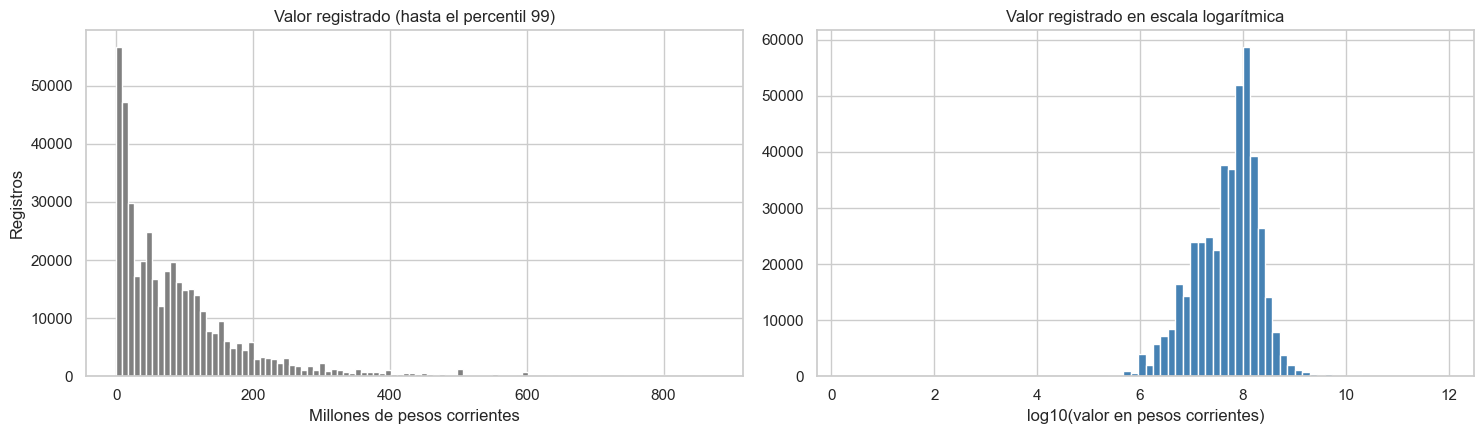

anio_escritura,2015,2016,2017,2018,2019,2020,2021,2022,2023
valor mediano (millones de pesos),,,,,,,,,
corrientes,47.70,48.26,54.00,58.00,78.00,70.48,75.00,83.50,96.07
constantes de 2023,74.54,69.86,75.25,78.48,101.91,89.89,93.49,93.11,96.49


In [9]:
u = d[d["incluido_universo_modelado"]]
claridad = (u["valor"] / 1e6).describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("valor (millones de pesos corrientes)")
claridad.loc["asimetría del valor"] = u["valor"].skew()
claridad.loc["asimetría del log-valor"] = np.log(u["valor"]).skew()
display(claridad)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(u["valor"] / 1e6, bins=100, range=(0, u["valor"].quantile(0.99) / 1e6), color="gray", edgecolor="white")
axes[0].set_title("Valor registrado (hasta el percentil 99)")
axes[0].set_xlabel("Millones de pesos corrientes")
axes[0].set_ylabel("Registros")
axes[1].hist(np.log10(u["valor"]), bins=80, color="steelblue", edgecolor="white")
axes[1].set_title("Valor registrado en escala logarítmica")
axes[1].set_xlabel("log10(valor en pesos corrientes)")
plt.tight_layout()
plt.show()

# Pesos constantes de 2023: valor x (IPC promedio de 2023 / IPC del mes de la escritura)
ipc_2023 = ipc.loc[ipc["anio"] == 2023, "ipc"].mean()
d["valor_constante_2023"] = d["valor"] * ipc_2023 / d["ipc"]
u = d[d["incluido_universo_modelado"]]
medianas = pd.DataFrame({
    "corrientes": u.groupby("anio_escritura")["valor"].median() / 1e6,
    "constantes de 2023": u.groupby("anio_escritura")["valor_constante_2023"].median() / 1e6,
}).loc[2015:2023]
display(medianas.T.rename_axis("valor mediano (millones de pesos)"))

## 1.7 Formato

Formatos de la fecha de la escritura, y verificación de si el lote con fecha en guiones coincide con los registros sin estado del folio (indicio de una procedencia distinta dentro de la consolidación del IGAC).

In [10]:
doc = d["documento_justificativo"]
formato_guion = doc.str.contains(r"\bDEL?\s+\d{1,2}-\d{1,2}-\d{2,4}\b", regex=True)
formatos = pd.Series({
    "DE dd/mm/aaaa": doc.str.contains(r"\bDE\s+\d{1,2}/\d{1,2}/\d{4}\b", regex=True).sum(),
    "DEL dd/mm/aa": doc.str.contains(r"\bDEL\s+\d{1,2}/\d{1,2}/\d{2}\b", regex=True).sum(),
    "DE dd-mm-aaaa": formato_guion.sum(),
}, name="registros")
display(formatos.to_frame().assign(**{"% de la base": formatos / len(d) * 100}))
print(f"Fecha de escritura legible: {d['fecha_escritura'].notna().mean() * 100:.1f}%")

display(pd.crosstab(d["estado_folio"].isna(), formato_guion,
                    rownames=["sin estado_folio"], colnames=["fecha con guiones"]))
lote = d[d["estado_folio"].isna()]
print("Prefijo del documento en el lote:", lote["documento_justificativo"].str[:3].value_counts().to_dict())
print("Oficinas de registro del lote:", lote["orip"].value_counts().to_dict())
print("Años de radicación del lote:", {int(k): int(v) for k, v in lote["year_radica"].value_counts().sort_index().items()})

# Estructura del pk: 6 piezas, la última es el año
partes = d["pk"].str.split("-")
print(f"\npk con 6 piezas: {(partes.str.len() == 6).mean() * 100:.2f}% | última pieza = año: {(partes.str[-1] == d['year_radica'].astype(str)).mean() * 100:.2f}%")
print(f"DIVIPOLA con 5 dígitos: {(d['divipola'].str.len() == 5).mean() * 100:.1f}%")

,registros,% de la base
DE dd/mm/aaaa,351748,76.88
DEL dd/mm/aa,82617,18.06
DE dd-mm-aaaa,23193,5.07


Fecha de escritura legible: 100.0%


fecha con guiones,False,True
sin estado_folio,,
False,434365,0
True,0,23193


Prefijo del documento en el lote: {'01-': 23184, '16-': 9}
Oficinas de registro del lote: {'282': 12605, '106': 10588}
Años de radicación del lote: {2015: 1594, 2016: 2946, 2017: 2586, 2018: 2490, 2019: 2321, 2020: 2196, 2021: 3341, 2022: 3386, 2023: 2333}

pk con 6 piezas: 100.00% | última pieza = año: 100.00%
DIVIPOLA con 5 dígitos: 100.0%
